# Stacking: 70/15/15 holdout and leave-one-out evaluation

Combine **logistic regression, random forest, XGBoost, and LightGBM** using a logistic-regression meta-model. The meta-model learns from the base models' out-of-fold positive-class probabilities rather than their in-sample predictions.

Evaluate the same fixed stacking specification with two strategies:

1. **Stratified 70/15/15:** fit on training data, report validation performance, then refit on training + validation and report test performance.
2. **Outer LOOCV:** hold out each row once, build the entire stack on the remaining rows, and collect one held-out probability per row. Calculate metrics from all collected predictions.

Each stack uses **three-fold stratified inner cross-validation** to train its meta-model. This inner splitting is separate from the outer evaluation. Preprocessing and feature selection live inside each base-model pipeline, so they are refitted within the inner folds too.

The dataset and test split were explored in earlier notebooks. These results are internal comparative estimates, not fresh independent confirmation. Hyperparameters are fixed here; no full-dataset tuning or selection from previous test results is performed.

In [1]:
# If needed, uncomment and run once:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn xgboost lightgbm
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, log_loss,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
RANDOM_STATE = 42
TARGET = "gallstone_status"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import LeaveOneOut
from time import perf_counter

## 1. Load the raw data

Retain the original target codes (positive class = `1`). The row-level split assumes one independent patient per row; if repeated patient identifiers become available, use grouped evaluation instead. Duplicate records must be reviewed before running.

In [2]:
candidates = [Path("dataset_gallstone"), Path("dataset_gallstone.xlsx"),
              Path("INFOSYS722/Iteration3_OpenStack/dataset_gallstone"),
              Path("INFOSYS722/Iteration3_OpenStack/dataset_gallstone.xlsx")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place the dataset beside this notebook or run from the projects directory.")
data = pd.read_excel(DATA_PATH) if DATA_PATH.suffix == ".xlsx" else pd.read_csv(DATA_PATH)
removed_index_cols = []
for c in list(data.columns):
    if str(c).startswith("Unnamed:") or not str(c).strip():
        values = pd.to_numeric(data[c], errors="coerce").to_numpy()
        if any(np.array_equal(values, np.arange(start, len(data) + start)) for start in [0, 1]):
            removed_index_cols.append(c)
data = data.drop(columns=removed_index_cols)
assert TARGET in data and data[TARGET].notna().all(), "Target must exist and have no missing values."
assert set(data[TARGET].unique()) == {0, 1}, "This notebook expects a binary target coded 0/1."
# A row-level split cannot protect against repeated patients without a patient identifier.
assert not data.duplicated().any(), "Review duplicate records before creating a row-level split."
X = data.drop(columns=TARGET).replace([np.inf, -np.inf], np.nan)
y = data[TARGET].astype(int)
print(f"Loaded {len(data)} rows and {X.shape[1]} raw predictors; removed index columns: {removed_index_cols}")
print("If patients have multiple records, replace the row split with patient-grouped splitting.")
display(data.head())

Loaded 319 rows and 38 raw predictors; removed index columns: ['Unnamed: 0']
If patients have multiple records, replace the row split with patient-grouped splitting.


,gallstone_status,age,gender,comorbidity,cad,hypothyroidism,hyperlipidemia,dm,height,weight,bmi,tbw,ecw,icw,ecf_tbw,tbfr_pct,lm_pct,protein_pct,vfr,bm,mm,obesity_pct,tfc,vfa,vma_kg,hfa,glucose,tc,ldl,hdl,triglyceride,ast,alt,alp,creatinine,gfr,crp,hgb,vitamin_d
0,0,50,0,0,0,0,0,0,185,92.8,27.1,52.9,21.2,31.7,40.0,19.2,80.84,18.88,9,3.7,71.4,23.4,17.8,10.6,39.7,0,102.0,250.0,175.0,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,30.5,43.1,19.5,23.6,45.0,32.8,67.20,16.68,15,3.2,60.3,38.8,31.0,18.4,32.7,0,94.0,172.0,108.0,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,31.2,47.2,20.1,27.1,43.0,27.3,72.67,16.35,15,3.3,62.9,41.7,24.9,16.2,34.0,0,103.0,179.0,124.0,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,24.0,41.4,17.0,24.4,41.0,15.8,84.19,16.90,6,2.9,54.1,9.0,10.7,6.5,29.2,1,69.0,173.0,73.0,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,28.3,51.4,20.0,31.4,39.0,20.0,80.02,16.81,8,3.5,68.2,28.6,17.9,10.4,37.4,2,109.0,205.0,154.0,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


## 2. Define a leakage-aware stack

Each base model median-imputes continuous measurements, imputes and one-hot encodes categories, and selects the top **75%** of encoded features using ANOVA F-scores. Logistic regression additionally uses StandardScaler; tree models leave numeric scales unchanged. Selection is a fixed baseline choice and can miss feature interactions.

The meta-model receives four probabilities, one per base model (`passthrough=False`). Its training probabilities come from held-out inner folds. After creating these probabilities, stacking refits each base pipeline on all data supplied to that stack. The meta-model uses StandardScaler and logistic regression.

Modest fixed tree counts and three inner folds keep LOOCV practical. Outer LOOCV still requires 319 complete stack fits; each stack fits four base models four times (three inner fits plus a full refit).

In [3]:
coded_fields = ["gender", "comorbidity", "cad", "hypothyroidism", "hyperlipidemia", "dm", "hfa"]
categorical_features = [c for c in X if c in coded_fields or not pd.api.types.is_numeric_dtype(X[c])]
numeric_features = [c for c in X if c not in categorical_features]
print("Numeric measurements:", numeric_features)
print("Categorical predictors:", categorical_features)
def make_preprocessor(scale_numeric=False):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler() if scale_numeric else "passthrough"),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric, numeric_features),
        ("categorical", categorical, categorical_features),
    ], remainder="drop")
def make_pipeline(model, scale_numeric=False):
    return Pipeline([
        ("preprocess", make_preprocessor(scale_numeric)),
        ("select", SelectPercentile(score_func=f_classif, percentile=75)),
        ("model", model),
    ])

def make_stack():
    base_models = [
        ("logistic", make_pipeline(LogisticRegression(C=1.0, max_iter=3000,
                                                       random_state=RANDOM_STATE), True)),
        ("random_forest", make_pipeline(RandomForestClassifier(
            n_estimators=60, max_depth=5, min_samples_leaf=4,
            n_jobs=1, random_state=RANDOM_STATE))),
        ("xgboost", make_pipeline(XGBClassifier(
            n_estimators=60, learning_rate=0.05, max_depth=2, reg_lambda=1.0,
            subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
            tree_method="hist", n_jobs=1, random_state=RANDOM_STATE))),
        ("lightgbm", make_pipeline(LGBMClassifier(
            n_estimators=60, learning_rate=0.05, num_leaves=7, min_child_samples=20,
            colsample_bytree=0.8, deterministic=True, force_col_wise=True,
            verbosity=-1, n_jobs=1, random_state=RANDOM_STATE))),
    ]
    meta_model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOM_STATE)),
    ])
    return StackingClassifier(
        estimators=base_models, final_estimator=meta_model,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        stack_method="predict_proba", passthrough=False, n_jobs=1)

stack_template = make_stack()
print("Base models:", [name for name, _ in stack_template.estimators])
print("Feature roles come from fixed schema/dtypes; no full-data outcome ranking is used.")

Numeric measurements: ['age', 'height', 'weight', 'bmi', 'tbw', 'ecw', 'icw', 'ecf_tbw', 'tbfr_pct', 'lm_pct', 'protein_pct', 'vfr', 'bm', 'mm', 'obesity_pct', 'tfc', 'vfa', 'vma_kg', 'glucose', 'tc', 'ldl', 'hdl', 'triglyceride', 'ast', 'alt', 'alp', 'creatinine', 'gfr', 'crp', 'hgb', 'vitamin_d']
Categorical predictors: ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
Base models: ['logistic', 'random_forest', 'xgboost', 'lightgbm']
Feature roles come from fixed schema/dtypes; no full-data outcome ranking is used.


## 3. Common evaluation helpers

Use probability threshold **0.5** throughout; do not optimise it on test or LOOCV predictions. Report ROC-AUC, average precision, accuracy, balanced accuracy, precision, recall, F1, and log loss. Apparent training scores are displayed only as an overfitting diagnostic.

A single LOOCV fold contains only one observation, so fold-level ROC-AUC is undefined. Compute ROC-AUC on the pooled held-out predictions, not by averaging single-row fold scores.

In [4]:
def evaluate_probabilities(target, probabilities):
    prediction = (probabilities >= 0.5).astype(int)
    return {"roc_auc": roc_auc_score(target, probabilities),
            "average_precision": average_precision_score(target, probabilities),
            "accuracy": accuracy_score(target, prediction),
            "balanced_accuracy": balanced_accuracy_score(target, prediction),
            "precision": precision_score(target, prediction, zero_division=0),
            "recall": recall_score(target, prediction, zero_division=0),
            "f1": f1_score(target, prediction, zero_division=0),
            "log_loss": log_loss(target, probabilities, labels=[0, 1])}

def plot_evaluation(target, probability, title):
    prediction = (np.asarray(probability) >= 0.5).astype(int)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    ConfusionMatrixDisplay.from_predictions(target, prediction, ax=axes[0], colorbar=False)
    RocCurveDisplay.from_predictions(target, probability, ax=axes[1], name="Stacking")
    PrecisionRecallDisplay.from_predictions(target, probability, ax=axes[2], name="Stacking")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[2].axhline(np.mean(target), linestyle="--", color="grey")
    axes[0].set_title("Confusion matrix (threshold 0.5)")
    axes[1].set_title("ROC"); axes[2].set_title("Precision–recall")
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

## 4. Strategy A — stratified 70/15/15

Keep the same seed and split logic as the feature-engineering notebook (223 training, 48 validation, 48 test rows). Evaluate the fixed stack on validation, without changing its settings. Then refit a fresh stack on the 271 development rows and evaluate test once in this run. Report training scores from the original 223-row fit separately from held-out scores.

In [5]:
X_train, X_reserved, y_train, y_reserved = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_reserved, y_reserved, test_size=0.50, stratify=y_reserved, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_valid) + len(X_test) == len(X)
split_summary = pd.DataFrame([
    {"split": name, "rows": len(target), "fraction": len(target) / len(y),
     "class_0": int((target == 0).sum()), "class_1": int((target == 1).sum())}
    for name, target in [("train", y_train), ("validation", y_valid), ("test", y_test)]
])
display(split_summary)
# Preserve row membership for reproducibility; these are source row indices, not patient IDs.
split_membership = pd.concat([
    pd.Series(name, index=frame.index, name="split")
    for name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]
]).sort_index().rename_axis("source_row")

,split,rows,fraction,class_0,class_1
0,train,223,0.69906,113,110
1,validation,48,0.15047,24,24
2,test,48,0.15047,24,24


              precision    recall  f1-score   support

           0      0.833     0.833     0.833        24
           1      0.833     0.833     0.833        24

    accuracy                          0.833        48
   macro avg      0.833     0.833     0.833        48
weighted avg      0.833     0.833     0.833        48

Holdout workflow runtime: 0.6 seconds


,evaluation,rows,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,log_loss
0,Apparent training (not held out),223,0.972,0.972,0.901,0.901,0.915,0.882,0.898,0.270
1,70/15/15 validation,48,0.901,0.925,0.792,0.792,0.792,0.792,0.792,0.387


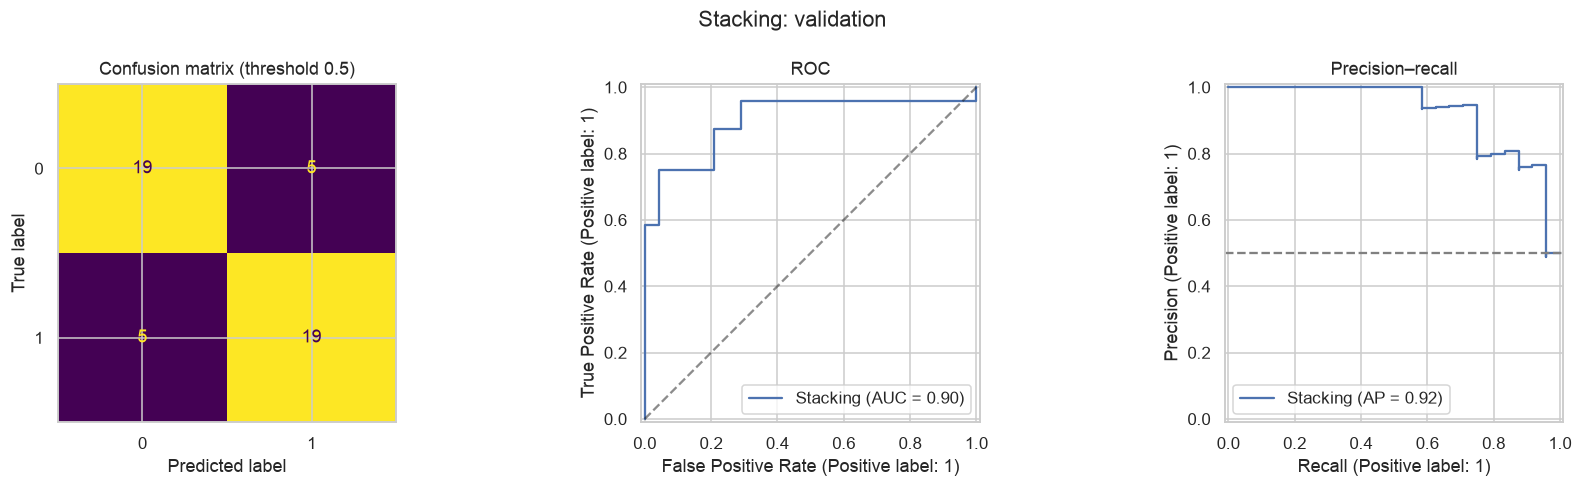

,evaluation,rows,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,log_loss
0,Apparent training (not held out),223,0.972,0.972,0.901,0.901,0.915,0.882,0.898,0.270
1,70/15/15 validation,48,0.901,0.925,0.792,0.792,0.792,0.792,0.792,0.387
2,70/15/15 test (refit on 85%),48,0.920,0.930,0.833,0.833,0.833,0.833,0.833,0.381


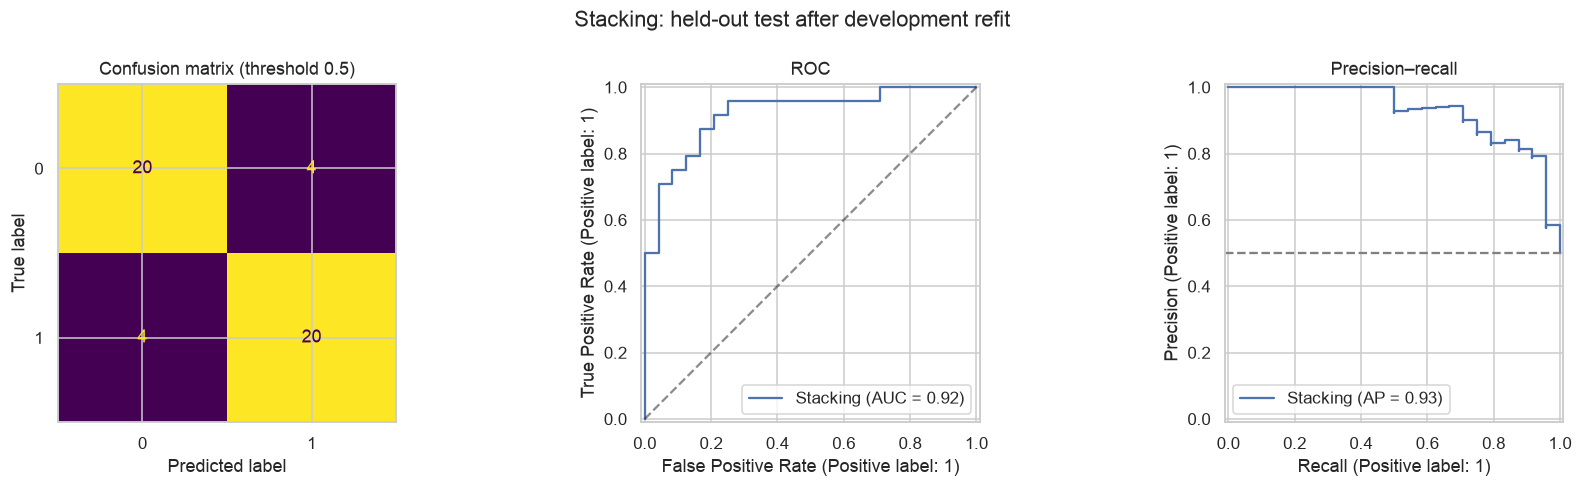

In [6]:
holdout_start = perf_counter()
training_stack = make_stack().fit(X_train, y_train)
train_probability = training_stack.predict_proba(X_train)[:, 1]
valid_probability = training_stack.predict_proba(X_valid)[:, 1]
holdout_rows = [
    {"evaluation": "Apparent training (not held out)", "rows": len(y_train),
     **evaluate_probabilities(y_train, train_probability)},
    {"evaluation": "70/15/15 validation", "rows": len(y_valid),
     **evaluate_probabilities(y_valid, valid_probability)},
]
display(pd.DataFrame(holdout_rows).round(3))
plot_evaluation(y_valid, valid_probability, "Stacking: validation")
# Settings are fixed before inspecting test predictions.
X_development = pd.concat([X_train, X_valid])
y_development = pd.concat([y_train, y_valid])
holdout_stack = make_stack().fit(X_development, y_development)
test_probability = holdout_stack.predict_proba(X_test)[:, 1]
holdout_seconds = perf_counter() - holdout_start
holdout_rows.append({"evaluation": "70/15/15 test (refit on 85%)", "rows": len(y_test),
                     **evaluate_probabilities(y_test, test_probability)})
holdout_results = pd.DataFrame(holdout_rows)
display(holdout_results.round(3))
plot_evaluation(y_test, test_probability, "Stacking: held-out test after development refit")
print(classification_report(y_test, (test_probability >= 0.5).astype(int), digits=3, zero_division=0))
print(f"Holdout workflow runtime: {holdout_seconds:.1f} seconds")

## 5. Strategy B — outer leave-one-out cross-validation

For each source row, fit a **new complete stack on the other 318 rows** and predict only the omitted row. Inner three-fold stacking, imputation, scaling, encoding, and feature selection are repeated for every outer training set. Do not construct full-dataset stacked features first: that would allow outer held-out rows to influence training.

This experiment pools all 319 observations and therefore also uses rows reserved for the separate holdout experiment. The two reported strategies are not independent datasets. LOOCV training sets overlap heavily; do not treat the 319 scores as independent fold-level performance estimates or use their standard deviation as a confidence interval.

LOOCV 1/319 complete; elapsed 0.2s
LOOCV 40/319 complete; elapsed 10.2s
LOOCV 80/319 complete; elapsed 20.8s
LOOCV 120/319 complete; elapsed 31.6s
LOOCV 160/319 complete; elapsed 42.0s
LOOCV 200/319 complete; elapsed 52.2s
LOOCV 240/319 complete; elapsed 62.2s
LOOCV 280/319 complete; elapsed 72.0s
LOOCV 319/319 complete; elapsed 81.9s
              precision    recall  f1-score   support

           0      0.769     0.807     0.788       161
           1      0.793     0.753     0.773       158

    accuracy                          0.781       319
   macro avg      0.781     0.780     0.780       319
weighted avg      0.781     0.781     0.780       319



,evaluation,rows,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,log_loss
0,Outer LOOCV (pooled held-out predictions),319,0.875,0.886,0.781,0.78,0.793,0.753,0.773,0.441


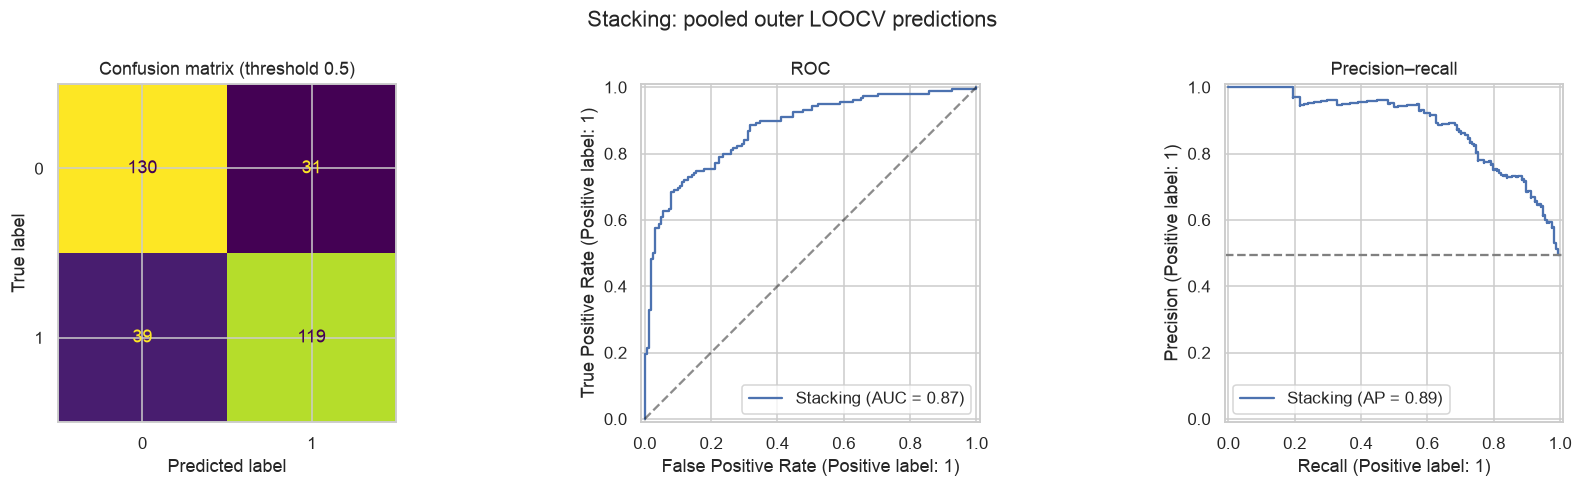

In [7]:
loo = LeaveOneOut()
loo_probability = np.full(len(y), np.nan)
loo_seen = np.zeros(len(y), dtype=int)
loo_start = perf_counter()
for fold, (train_positions, test_positions) in enumerate(loo.split(X, y), start=1):
    assert not np.intersect1d(train_positions, test_positions).size
    fold_stack = make_stack()
    fold_stack.fit(X.iloc[train_positions], y.iloc[train_positions])
    loo_probability[test_positions] = fold_stack.predict_proba(X.iloc[test_positions])[:, 1]
    loo_seen[test_positions] += 1
    if fold == 1 or fold % 40 == 0 or fold == len(y):
        print(f"LOOCV {fold}/{len(y)} complete; elapsed {perf_counter() - loo_start:.1f}s", flush=True)
loo_seconds = perf_counter() - loo_start
assert np.all(loo_seen == 1), "Every observation must be evaluated exactly once."
assert np.isfinite(loo_probability).all()
assert np.all((loo_probability >= 0) & (loo_probability <= 1))
loo_results = pd.DataFrame([{"evaluation": "Outer LOOCV (pooled held-out predictions)",
                             "rows": len(y), **evaluate_probabilities(y, loo_probability)}])
display(loo_results.round(3))
plot_evaluation(y, loo_probability, "Stacking: pooled outer LOOCV predictions")
print(classification_report(y, (loo_probability >= 0.5).astype(int), digits=3, zero_division=0))

## 6. Compare the strategies and inspect the meta-model

Compare held-out test and pooled LOOCV metrics, remembering that their evaluation sample sizes (48 versus 319) and fitted training sizes (271 versus 318) differ. A higher score does not establish that an evaluation strategy or model is superior. Validation and apparent training rows provide additional context, but should not be presented as final test estimates.

The meta-model coefficients below belong to the development-fitted holdout stack. They indicate how it combines standardised base-model probabilities. Correlated base-model outputs can make weights unstable; coefficients are not standalone base-model performance rankings.

Runtime: holdout 0.6s; LOOCV 81.9s


,evaluation,rows,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,log_loss
0,Apparent training (not held out),223,0.972,0.972,0.901,0.901,0.915,0.882,0.898,0.270
1,70/15/15 validation,48,0.901,0.925,0.792,0.792,0.792,0.792,0.792,0.387
2,70/15/15 test (refit on 85%),48,0.920,0.930,0.833,0.833,0.833,0.833,0.833,0.381
3,Outer LOOCV (pooled held-out predictions),319,0.875,0.886,0.781,0.780,0.793,0.753,0.773,0.441


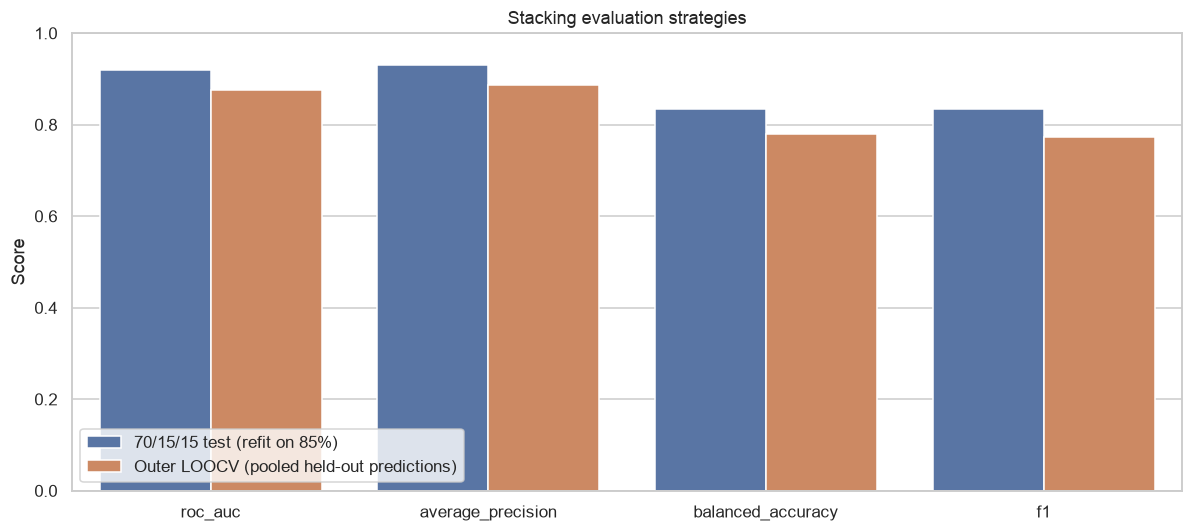

,base_model,meta_coefficient
0,logistic,0.989932
1,random_forest,-0.287712
2,xgboost,0.501558
3,lightgbm,0.692767


In [8]:
comparison = pd.concat([holdout_results, loo_results], ignore_index=True)
display(comparison.round(3))
heldout_comparison = pd.concat([holdout_results.tail(1), loo_results], ignore_index=True)
plot_table = heldout_comparison.melt(id_vars=["evaluation", "rows"],
    value_vars=["roc_auc", "average_precision", "balanced_accuracy", "f1"],
    var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_table, x="metric", y="score", hue="evaluation", ax=ax)
ax.set(ylim=(0, 1), title="Stacking evaluation strategies", xlabel="", ylabel="Score")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
meta_coefficients = pd.DataFrame({
    "base_model": [name for name, _ in holdout_stack.estimators],
    "meta_coefficient": holdout_stack.final_estimator_.named_steps["logistic"].coef_[0],
})
display(meta_coefficients)
print(f"Runtime: holdout {holdout_seconds:.1f}s; LOOCV {loo_seconds:.1f}s")

## 7. Save metrics and held-out predictions

Outputs are saved to `stacking_results` beside the dataset. Source row indices preserve alignment and are not patient identifiers. The held-out probabilities can support later error analysis, but using them to tune the model would require a new evaluation. `holdout_stack` remains available in memory for predictions; the final LOOCV fold model is not a final production model.

In [9]:
RESULTS_DIR = DATA_PATH.parent / "stacking_results"
RESULTS_DIR.mkdir(exist_ok=True)
comparison.to_csv(RESULTS_DIR / "evaluation_metrics.csv", index=False)
split_membership.to_csv(RESULTS_DIR / "split_membership.csv")
pd.DataFrame({"source_row": X_valid.index, "actual": y_valid.to_numpy(),
              "probability_1": valid_probability, "prediction": (valid_probability >= 0.5).astype(int)
             }).to_csv(RESULTS_DIR / "validation_predictions.csv", index=False)
pd.DataFrame({"source_row": X_test.index, "actual": y_test.to_numpy(),
              "probability_1": test_probability, "prediction": (test_probability >= 0.5).astype(int)
             }).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
pd.DataFrame({"source_row": X.index, "actual": y.to_numpy(),
              "probability_1": loo_probability, "prediction": (loo_probability >= 0.5).astype(int)
             }).to_csv(RESULTS_DIR / "loocv_predictions.csv", index=False)
meta_coefficients.to_csv(RESULTS_DIR / "holdout_meta_coefficients.csv", index=False)
print("Saved results to", RESULTS_DIR.resolve())

Saved results to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/stacking_results
